In [1]:
import sys; sys.path.append("..")
from src.data import load_data
from src.pipelines import get_baselines
from src.experiment_log import ExperimentLogger

X_train, _, y_train, _, labels = load_data()
lg = ExperimentLogger("tuan")        

for name, model in get_baselines().items():
    lg.run(model, X_train, y_train, name, notes="baseline")

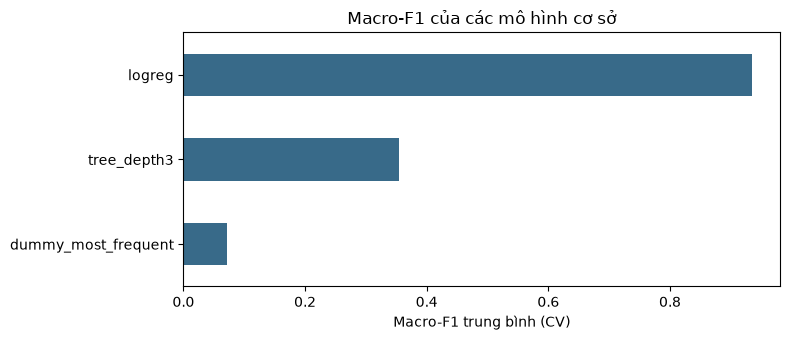

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

results = (Path('..') if Path.cwd().name == 'experiments' else Path('.')) / 'results'
models = ['dummy_most_frequent', 'logreg', 'tree_depth3']
values = pd.concat([pd.read_csv(results / f'cv/{name}.csv') for name in models]).groupby('model')['macro_f1'].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
values.sort_values().plot.barh(ax=ax, color='#386A89')
ax.set(title='Macro-F1 của các mô hình cơ sở', xlabel='Macro-F1 trung bình (CV)', ylabel='')
fig.tight_layout()
(results / 'figures').mkdir(exist_ok=True)
fig.savefig(results / 'figures/baseline_macro_f1.png', dpi=300, bbox_inches='tight')
plt.show()